# 5장 3강: 배깅 vs 부스팅 선택과 모델 해석(SHAP)

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 배깅과 부스팅을 비교하고, SHAP으로 앙상블 모델의 예측 근거를 해석합니다.

- Random Forest와 XGBoost의 구조적 차이를 비교합니다.
- 성능과 학습 시간을 확인하여 상황에 맞는 모델 선택 기준을 정리합니다.
- Feature Importance의 특징과 한계를 확인합니다.
- TreeSHAP을 이용해 모델 전체의 **전역 해석**을 수행합니다.
- 특정 주택 한 건의 예측을 **지역 해석**합니다.
- SHAP 값의 부호를 이용하여 각 특성이 예측값을 올렸는지 내렸는지 설명합니다.

> 이 실습에서는 5장 3강 교안에 나온 배깅/부스팅 비교, Feature Importance, SHAP 전역·지역 해석 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- scikit-learn
- xgboost
- shap
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

### 사용할 특성

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `2ndFlrSF`
- `FullBath`
- `TotRmsAbvGrd`
- `YearBuilt`
- `YearRemodAdd`
- `Fireplaces`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 숫자형 특성과 `SalePrice`를 선택합니다.
3. Train / Test 데이터로 분리합니다.
4. Random Forest와 XGBoost를 같은 데이터에서 비교합니다.
5. SHAP은 XGBoost 모델을 대상으로 확인합니다.

In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

c:\ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train 크기: (1168, 12)
Test 크기: (292, 12)

[결측치]


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
GarageArea,0
TotalBsmtSF,0
1stFlrSF,0
2ndFlrSF,0
FullBath,0
TotRmsAbvGrd,0
YearBuilt,0


---

# 필수 1. 배깅과 부스팅 비교 및 선택

## 문제 1. Random Forest와 XGBoost를 비교하세요.

### 요구사항

다음 두 모델을 사용합니다.

```python
RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
```

각 모델에 대해 다음을 확인합니다.

1. Train 데이터로 학습합니다.
2. 학습 시간을 측정합니다.
3. Test 데이터를 예측합니다.
4. Test RMSE를 계산합니다.
5. Test R²를 계산합니다.
6. 결과를 하나의 DataFrame으로 정리합니다.

### 확인 포인트

- Random Forest가 배깅 계열이라는 점을 이해했는가?
- XGBoost가 부스팅 계열이라는 점을 이해했는가?
- 성능뿐 아니라 학습 시간도 함께 확인했는가?

In [3]:
# TODO
# Random Forest와 XGBoost의 Test RMSE, Test R², 학습 시간을 비교하세요.
results = []

rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

start = time.time()
rf.fit(X_train, y_train)
rf_time = time.time() - start

rf_pred = rf.predict(X_test)

rf_rmse = mean_squared_error(
    y_test,
    rf_pred
) ** 0.5

rf_r2 = r2_score(
    y_test,
    rf_pred
)

results.append([
    "Random Forest",
    rf_time,
    rf_rmse,
    rf_r2
])


xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

start = time.time()
xgb.fit(X_train, y_train)
xgb_time = time.time() - start

xgb_pred = xgb.predict(X_test)

xgb_rmse = mean_squared_error(
    y_test,
    xgb_pred
) ** 0.5

xgb_r2 = r2_score(
    y_test,
    xgb_pred
)

results.append([
    "XGBoost",
    xgb_time,
    xgb_rmse,
    xgb_r2
])


result_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Train Time",
        "Test RMSE",
        "Test R²"
    ]
)

display(result_df)

,Model,Train Time,Test RMSE,Test R²
0,Random Forest,0.510313,29206.646630,0.888789
1,XGBoost,2.574186,28405.320065,0.894807


### Q1. Random Forest와 XGBoost의 학습 방식은 어떻게 다른가요?

**답변:**  
- Random Forest / Bagging: 여러 나무를 독립적으로 학습하고 예측을 평균
- XGBoost / Boosting: 나무를 순차적으로 쌓으면서 앞 모델이 낲긴 오차를 다음 모델이 보완.

### Q2. 다음 상황에서 어떤 방식을 우선 후보로 생각할 수 있는지 작성하세요.

1. 빠르게 베이스라인을 만들고 싶고 튜닝 여력이 적음
 - Random Forest

2. 시간을 들여 예측 성능을 더 끌어올리고 싶음
 - Boosting 계열

3. 노이즈가 많아 과적합 위험을 조심해야 함
 - Random Forest를 우선 후보로 생각할 수 있음.

---

# 필수 2. Feature Importance와 SHAP 전역 해석

## 문제 1. XGBoost의 Feature Importance를 확인하세요.

### 요구사항

1. 필수 1에서 학습한 XGBoost 모델을 사용합니다.
2. `feature_importances_`를 이용합니다.
3. 특성명과 중요도를 DataFrame으로 만듭니다.
4. 중요도가 높은 순서대로 정렬합니다.
5. 막대그래프로 표시합니다.

### 확인 포인트

- 어떤 특성이 모델 전체에서 중요하게 사용되었는지 확인했는가?
- 중요도의 크기는 알 수 있지만 방향은 알 수 없다는 점을 이해했는가?

,Feature,Importance
0,OverallQual,0.466007
1,GarageCars,0.131052
2,GrLivArea,0.086469
3,1stFlrSF,0.061165
4,FullBath,0.046529
5,2ndFlrSF,0.042468
6,TotalBsmtSF,0.041869
7,Fireplaces,0.040955
8,YearRemodAdd,0.034265
9,YearBuilt,0.027039


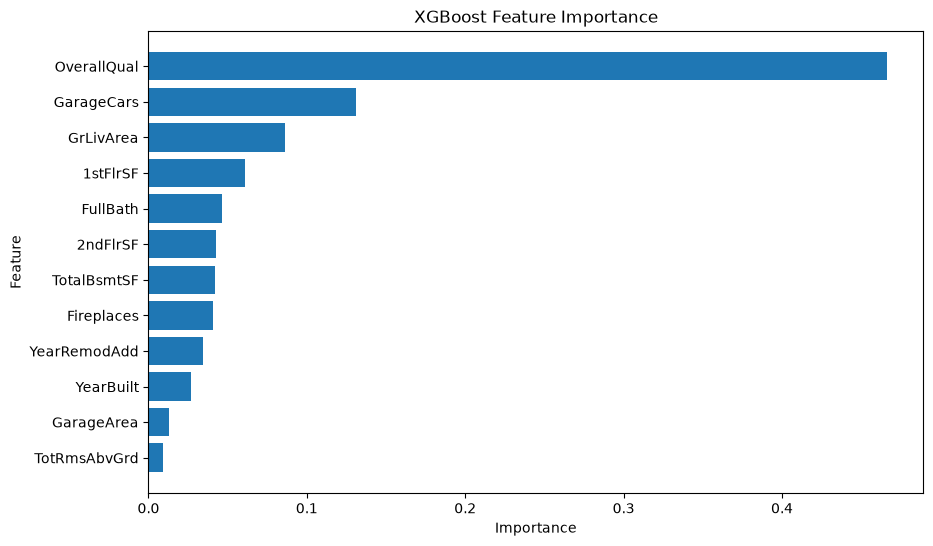

In [4]:
# TODO
# XGBoost의 Feature Importance를 표와 그래프로 확인하세요.
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")

plt.gca().invert_yaxis()

plt.show()

- OverallQual이 약 0.46으로 현재 모델에서 중요도를 차지하고 있다.
- GarageCars가 약 0.13으로 ㅎ녀재 모델에서 두 번째로 높은 중요도를 차지하고 있다.

### Q3. Feature Importance만으로는 알기 어려운 정보는 무엇인가요?

**답변:**  
- 예측을 높이는지, 낮추는지에 대한 방향성(음/양)
- 특정 샘플 한 건에 대한 개벽적인 기여도(중요도)에 근거

## 문제 2. TreeSHAP으로 전역 중요도를 확인하세요.

### 요구사항

1. `shap.TreeExplainer()`에 XGBoost 모델을 전달합니다.
2. Test 데이터의 SHAP 값을 계산합니다.
3. `shap.plots.bar()`로 전역 중요도를 확인합니다.
4. SHAP 절댓값의 평균도 계산하여 특성별 중요도를 DataFrame으로 정리합니다.
5. 상위 특성을 확인합니다.

### 확인 포인트

- SHAP은 각 특성이 예측값에 기여한 정도를 계산한다는 점을 이해했는가?
- 전역 SHAP에서는 여러 샘플의 기여도 크기를 종합해 전체 중요도를 볼 수 있는가?

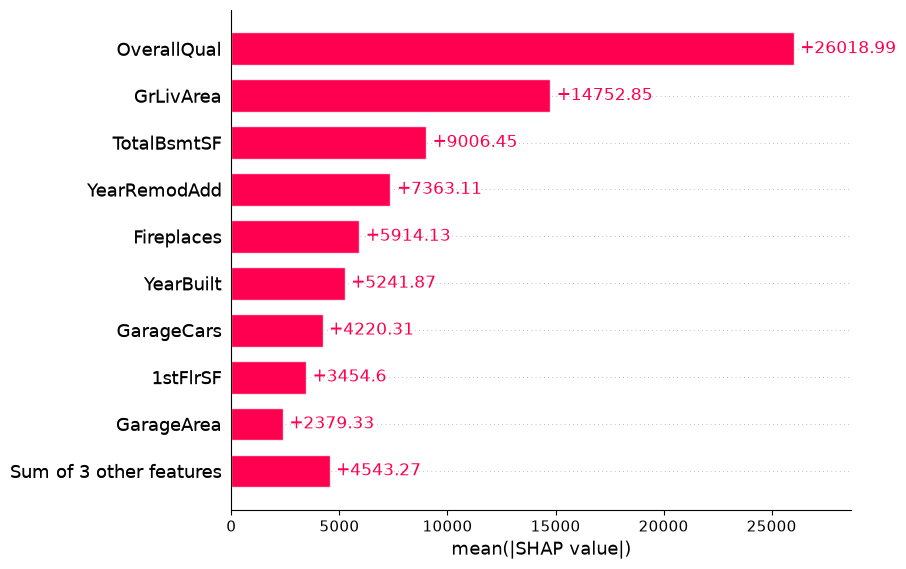

,Feature,Mean |SHAP Value|
0,OverallQual,26018.992188
1,GrLivArea,14752.852539
2,TotalBsmtSF,9006.452148
3,YearRemodAdd,7363.110352
4,Fireplaces,5914.131348
5,YearBuilt,5241.869141
6,GarageCars,4220.305664
7,1stFlrSF,3454.599609
8,GarageArea,2379.325684
9,2ndFlrSF,2307.338867


가장 중요한 Feature: OverallQual


In [5]:
# TODO
# TreeSHAP을 이용해 XGBoost 모델의 전역 SHAP 중요도를 확인하세요.
explainer = shap.TreeExplainer(xgb)

shap_values = explainer(X_test)

shap.plots.bar(shap_values)


shap_importance = np.abs(shap_values.values).mean(axis=0)

shap_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP Value|": shap_importance
})

shap_df = shap_df.sort_values(
    "Mean |SHAP Value|",
    ascending=False
).reset_index(drop=True)

display(shap_df)

print("가장 중요한 Feature:", shap_df.iloc[0]["Feature"])

OverallQual 26,019의 의미
- Test 주택 각각에서 품질에 배분된 SHAP 값의 절대값을 평균했더니 26,019 가격 단위였다는 뜻

막대가 빨간색이고 +표시가 있는 건 상승인가?
- 아니다. |SHAP Value| 절대값이기 때문에 항상 예측이 양인 것을 의미하는 것은 아니다.

기존 중요도와 ㅅ누위가 다른 이유?
- 기존 모델에서 Feature Importance에서는 GarageCars가 2위였는데, SHAP에서는 7위이다.
- SHAP에서는 Test 주택 예측 차이에 배분한 기여 크기를 평균하기 때문에 앞서 Feature Importance와 계산 원리와 집계 대상이 다르기 때문에 기존 중요도와 순위가 다를 수 있다.

### Q4. Feature Importance와 SHAP의 가장 큰 차이는 무엇인가요?

**답변:**  
- Feature Importance는 주로 모델 전체에서 중요도의 크기를 보여 준다면
- SHAP은 전역 중요도, 개별 예측을 설명할 때, 각 특성의 양수/음수의 방향성을 보고 싶을 때까지 확인이 가능하다.

---
# 과제 1. 모델 비교·SHAP 해석과 특성 선택 전후 검증

## 배경
주택 가격 예측 모델을 성능과 학습 시간으로 비교하고, SHAP으로 예측 근거를 설명합니다. 이어서 중요한 특성을 선택했을 때 검증 성능이 어떻게 달라지는지 확인합니다.

> 필수 1·2는 연습용입니다. 아래 과제의 비교표·해석·코드를 제출하세요. 준비 단계의 `X_train`, `y_train`을 사용하되 과제용 모델을 새로 학습합니다. Test 결과로 모델이나 특성을 선택하지 않도록, Train 안에서 Validation을 분리합니다. 개별 주택 해석 대상도 Validation의 첫 번째 주택으로 맞춥니다.

## 요구사항

### 1. 같은 조건에서 모델 비교
1. `X_train`, `y_train`을 Train_sub / Validation으로 나누세요(`test_size=0.2`, `random_state=42`). 결측값이 있으면 Train_sub에서 구한 중앙값으로 두 데이터를 채우세요.
2. Random Forest(`n_estimators=200`)와 XGBoost(`n_estimators=200`, `learning_rate=0.05`, `max_depth=3`)를 같은 Train_sub에서 학습하세요. 두 모델 모두 `random_state=42`, `n_jobs=1`로 설정하세요.
3. 각 모델의 **fit에 걸린 시간**, Train_sub RMSE, Validation RMSE와 R²를 `model_comparison`으로 정리하세요. 시간은 같은 환경에서 측정하며, 한 번의 측정만으로 일반적인 속도 우열을 단정하지 마세요.
4. 예측 오차, 학습 시간, Train/Validation 오차 차이와 운영 목적을 근거로 우선 후보를 선택하세요. 모델 선택 결과와 관계없이 다음 해석은 XGBoost로 수행합니다.

### 2. Feature Importance와 SHAP 전역·지역 해석
5. 과제용 XGBoost의 `feature_importances_`와 **Train_sub의 평균 절댓값 SHAP**을 각각 순위로 정리하여 `importance_comparison`으로 비교하세요. 전역 SHAP 막대그래프도 제출하세요.
6. Validation의 첫 번째 주택의 실제 가격·예측가격을 확인하고 SHAP waterfall plot을 그리세요.
7. 해당 주택의 절댓값 SHAP 상위 5개 특성·특성값·SHAP 값을 `local_top5`로 정리하세요. 양수·음수의 의미를 설명하고 기준값 + 모든 SHAP 값의 합이 예측값과 거의 같은지 확인하세요.
8. 두 전역 중요도 산출 원리와 한계를 비교하고, 전역 순위와 개별 주택의 기여도가 다른 이유를 설명하세요.

### 3. 중요도에 근거한 특성 선택 및 검증
9. Train_sub의 평균 절댓값 SHAP이 높은 **상위 6개 특성**을 선택하세요. 특성 선택은 이번 과제의 특성 개선 시도입니다. 개수는 비교 결과를 보기 전에 6개로 고정합니다.
10. 선택한 특성만 사용하여 동일한 XGBoost 설정으로 다시 학습하세요. 기존 모델과 동일한 Train_sub / Validation 행을 사용하고, 특성 이외의 조건은 유지하세요.
11. 전체 특성 모델과 선택 특성 모델의 특성 수·학습 시간·Train RMSE·Validation RMSE·Validation R²를 `feature_comparison`으로 비교하세요. `기존 Validation RMSE - 선택 후 Validation RMSE`와 기존 대비 개선율(%)을 계산하세요.
12. 개선 여부와 채택 여부를 수치로 설명하세요. 성능이 나빠져도 원인 가능성과 한계를 타당하게 설명하면 됩니다. 검증 결과를 반복 확인하며 특성을 바꾸지 말고, 최종 일반화 성능 확인에는 별도 Test 평가가 필요함을 밝히세요.

## 해석 질문

### Q5. 전역 SHAP에서 가장 중요한 특성이 특정 주택에서도 반드시 가장 큰 영향을 주나요?
### Q6. SHAP 값이 양수/음수라는 것은 각각 무엇을 의미하나요?
### Q7. 두 모델 중 무엇을 우선 후보로 선택했나요? 성능·학습 시간·과적합 징후와 주택 가격 예측 업무를 연결하여 설명하세요.
### Q8. Feature Importance와 평균 절댓값 SHAP의 계산 원리와 한계는 무엇이며, 실제 상위 특성 순위는 어떻게 다른가요?
### Q9. 상위 6개 특성은 무엇이며, 선택 전후 RMSE 차이와 개선율은 얼마인가요? 이 시도를 채택할지와 판단의 한계를 설명하세요.

## 제출물 / 확인 포인트
- `model_comparison`, `importance_comparison`, 전역 SHAP 그래프
- 개별 주택의 실제값·예측값·waterfall plot·`local_top5`·SHAP 합 검증
- 선택한 6개 특성, `feature_comparison`, RMSE 차이와 개선율
- 계산 코드와 Q5~Q9 답변
- 동일한 검증 조건 유지, SHAP의 방향·전역/지역 구분, 관측한 개선 여부와 해석의 한계

In [6]:
# TODO 1: 같은 Train_sub / Validation으로 두 모델의 성능과 fit 시간을 비교하세요.
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

median_values = X_train_sub.median()

X_train_sub = X_train_sub.fillna(median_values)
X_val = X_val.fillna(median_values)

results = []

task_rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=1
)

start = time.time()
task_rf.fit(X_train_sub, y_train_sub)
rf_time = time.time() - start

rf_train_pred = task_rf.predict(X_train_sub)
rf_val_pred = task_rf.predict(X_val)

rf_train_rmse = mean_squared_error(
    y_train_sub,
    rf_train_pred
) ** 0.5

rf_val_rmse = mean_squared_error(
    y_val,
    rf_val_pred
) ** 0.5

rf_val_r2 = r2_score(
    y_val,
    rf_val_pred
)

results.append([
    "Random Forest",
    rf_time,
    rf_train_rmse,
    rf_val_rmse,
    rf_val_r2
])


task_xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    n_jobs=1
)

start = time.time()
task_xgb.fit(X_train_sub, y_train_sub)
xgb_time = time.time() - start

xgb_train_pred = task_xgb.predict(X_train_sub)
xgb_val_pred = task_xgb.predict(X_val)

xgb_train_rmse = mean_squared_error(
    y_train_sub,
    xgb_train_pred
) ** 0.5

xgb_val_rmse = mean_squared_error(
    y_val,
    xgb_val_pred
) ** 0.5

xgb_val_r2 = r2_score(
    y_val,
    xgb_val_pred
)

results.append([
    "XGBoost",
    xgb_time,
    xgb_train_rmse,
    xgb_val_rmse,
    xgb_val_r2
])

model_comparison = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Fit Time",
        "Train RMSE",
        "Validation RMSE",
        "Validation R²"
    ]
)

display(model_comparison)

,Model,Fit Time,Train RMSE,Validation RMSE,Validation R²
0,Random Forest,0.400730,12367.658293,29317.762180,0.867024
1,XGBoost,0.030608,19116.641546,27436.846466,0.883539


,Feature,Feature Importance,Mean |SHAP Value|,FI Rank,SHAP Rank
0,OverallQual,0.427782,25416.365234,1,1
1,GrLivArea,0.078942,13777.564453,3,2
2,TotalBsmtSF,0.045537,9604.813477,6,3
3,YearRemodAdd,0.025395,7255.513184,9,4
4,Fireplaces,0.045971,6242.651367,5,5
5,YearBuilt,0.034376,6187.059570,7,6
6,GarageCars,0.205156,3490.014404,2,7
7,1stFlrSF,0.050895,3446.147461,4,8
8,GarageArea,0.016150,2788.530762,11,9
9,2ndFlrSF,0.033605,2005.598633,8,10


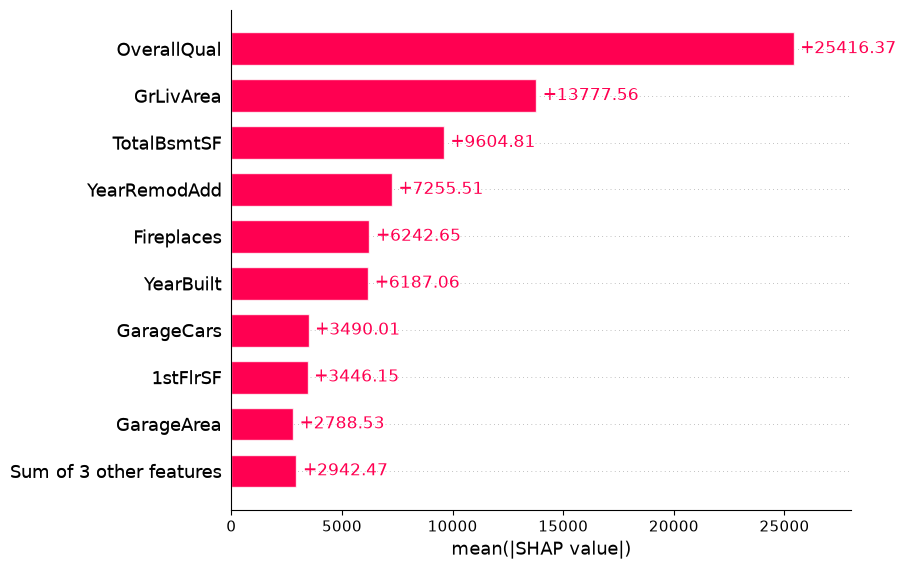

실제 가격: 140000
예측 가격: 149904.42


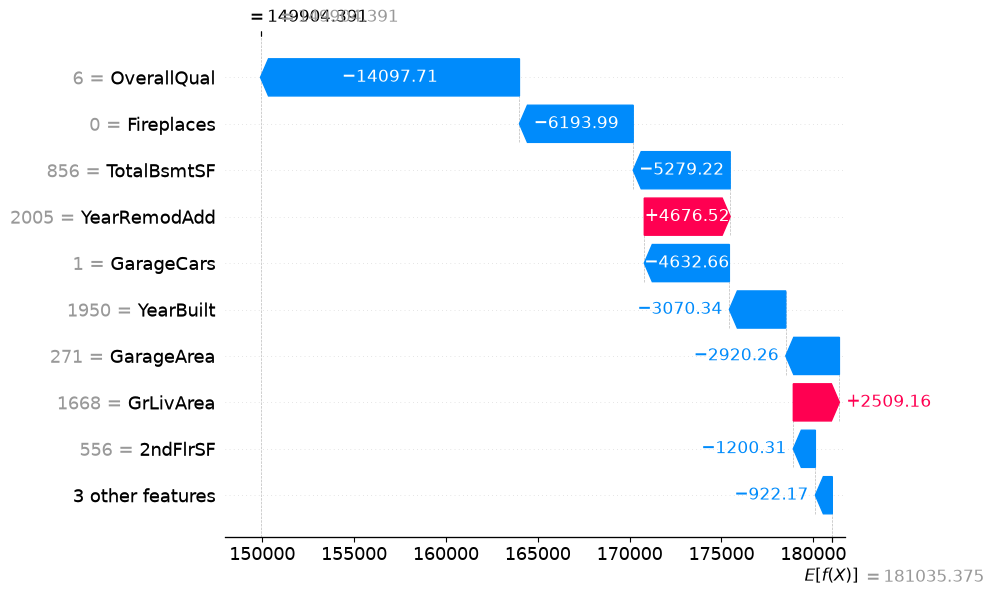

,Feature,Feature Value,SHAP Value,|SHAP Value|
0,OverallQual,6,-14097.710938,14097.710938
1,Fireplaces,0,-6193.989258,6193.989258
2,TotalBsmtSF,856,-5279.219727,5279.219727
3,YearRemodAdd,2005,4676.523438,4676.523438
4,GarageCars,1,-4632.663086,4632.663086


기준값: 181035.38
SHAP 값의 합: -31130.984
기준값 + SHAP 합: 149904.39
모델 예측값: 149904.42


In [8]:
# TODO 2: 과제용 XGBoost의 Feature Importance, Train_sub 전역 SHAP, Validation 첫 주택의 지역 SHAP을 확인하세요.
explainer = shap.TreeExplainer(task_xgb)

shap_train = explainer(X_train_sub)

shap_importance = np.abs(
    shap_train.values
).mean(axis=0)

importance_comparison = pd.DataFrame({
    "Feature": X_train_sub.columns,
    "Feature Importance": task_xgb.feature_importances_,
    "Mean |SHAP Value|": shap_importance
})

importance_comparison["FI Rank"] = (
    importance_comparison["Feature Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_comparison["SHAP Rank"] = (
    importance_comparison["Mean |SHAP Value|"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_comparison = importance_comparison.sort_values(
    "SHAP Rank"
).reset_index(drop=True)

display(importance_comparison)

shap.plots.bar(shap_train)


first_house = X_val.iloc[[0]]

first_actual = y_val.iloc[0]
first_pred = task_xgb.predict(first_house)[0]

print("실제 가격:", first_actual)
print("예측 가격:", first_pred)

shap_first = explainer(first_house)

shap.plots.waterfall(shap_first[0])


local_top5 = pd.DataFrame({
    "Feature": first_house.columns,
    "Feature Value": first_house.iloc[0].values,
    "SHAP Value": shap_first.values[0]
})

local_top5["|SHAP Value|"] = abs(
    local_top5["SHAP Value"]
)

local_top5 = local_top5.sort_values(
    "|SHAP Value|",
    ascending=False
).head(5).reset_index(drop=True)

display(local_top5)


base_value = shap_first.base_values[0]
shap_sum = shap_first.values[0].sum()
shap_prediction = base_value + shap_sum

print("기준값:", base_value)
print("SHAP 값의 합:", shap_sum)
print("기준값 + SHAP 합:", shap_prediction)
print("모델 예측값:", first_pred)

In [9]:
# TODO 3: Train_sub SHAP 상위 6개 특성으로 재학습하고 동일 Validation에서 전후 성능을 비교하세요.
selected_features = (
    importance_comparison
    .sort_values("Mean |SHAP Value|", ascending=False)
    .head(6)["Feature"]
    .tolist()
)

print("선택한 상위 6개 특성:", selected_features)


selected_xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    n_jobs=1
)

start = time.time()

selected_xgb.fit(
    X_train_sub[selected_features],
    y_train_sub
)

selected_time = time.time() - start


selected_train_pred = selected_xgb.predict(
    X_train_sub[selected_features]
)

selected_val_pred = selected_xgb.predict(
    X_val[selected_features]
)

selected_train_rmse = mean_squared_error(
    y_train_sub,
    selected_train_pred
) ** 0.5

selected_val_rmse = mean_squared_error(
    y_val,
    selected_val_pred
) ** 0.5

selected_val_r2 = r2_score(
    y_val,
    selected_val_pred
)


feature_comparison = pd.DataFrame({
    "Model": [
        "All Features",
        "Top 6 Features"
    ],
    "Feature Count": [
        X_train_sub.shape[1],
        len(selected_features)
    ],
    "Fit Time": [
        xgb_time,
        selected_time
    ],
    "Train RMSE": [
        xgb_train_rmse,
        selected_train_rmse
    ],
    "Validation RMSE": [
        xgb_val_rmse,
        selected_val_rmse
    ],
    "Validation R²": [
        xgb_val_r2,
        selected_val_r2
    ]
})

display(feature_comparison)


rmse_difference = (
    xgb_val_rmse
    - selected_val_rmse
)

improvement_rate = (
    rmse_difference
    / xgb_val_rmse
) * 100

print("기존 Validation RMSE - 선택 후 Validation RMSE:", rmse_difference)
print("개선율(%):", improvement_rate)

선택한 상위 6개 특성: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearRemodAdd', 'Fireplaces', 'YearBuilt']


,Model,Feature Count,Fit Time,Train RMSE,Validation RMSE,Validation R²
0,All Features,12,0.030608,19116.641546,27436.846466,0.883539
1,Top 6 Features,6,0.020854,20282.480322,30029.857143,0.860486


기존 Validation RMSE - 선택 후 Validation RMSE: -2593.0106764965094
개선율(%): -9.450833497602664


## Q5~Q9 답변

### Q5. 전역 SHAP에서 가장 중요한 특성이 특정 주택에서도 반드시 가장 큰 영향을 주나요?
- 아니다. 전역 SHAP은 전체 데이터에서의 중요도이고 개별 주택에서는 특성값에 따라 영향 크기가 달라질 수 있다.
- 이 주택에서는 전역 2위인 GrLivArea가 상위 5개에 없고 전역 7위인 GarageCars가 5위에 들어왔다.

### Q6. SHAP 값이 양수/음수라는 것은 각각 무엇을 의미하나요?
- SHAP 값이 양수면 기준값보다 예측가격을 높이는 방향
- 음수면 낮추는 방향으로 기여했다는 의미이다.

### Q7. 두 모델 중 무엇을 우선 후보로 선택했나요? 성능·학습 시간·과적합 징후와 주택 가격 예측 업무를 연결하여 설명하세요.
- XGBoost를 우선 후보로 선택한다.
- Validation RMSE가 27,436.85로 더 낮고 R²도 0.8835로 높으며, Train, Validation 차이도 Random Forest보다 작아 과적합 징후가 상대적으로 적었다.
- 학습 시간은 XGBoost 0.03초, Random Forest 0.40초였지만 시간은 환경에 따라 달라질 수 있어 항상 빠르다고 단정하는 것이 아닌 가격 예측 업무에서는 성능과 안정성을 함께 본다.

### Q8. Feature Importance와 평균 절댓값 SHAP의 계산 원리와 한계는 무엇이며, 실제 상위 특성 순위는 어떻게 다른가요?
- Feature Importance는 트리가 학습할 때 Feature를 얼마나 활용했는지, SHAP은 실제 예측에 얼마나 기여했는지를 본다.
- Feature Importance는 영향의 방향과 개별 예측 이유를 알기 어렵고 둘 다 인과관계는 아니다.
- 실제로 GarageCars는 FI2위인데 SHAP은 7위, TotalBsmtSF는 FI 6위에서 SHAP 3위로 순위 차이가 나타났다.

### Q9. 상위 6개 특성은 무엇이며, 선택 전후 RMSE 차이와 개선율은 얼마인가요? 이 시도를 채택할지와 판단의 한계를 설명하세요.
- OverallQual, GrLivArea, TotalBsmtSF, YearRemodAdd, Fireplaces, YearBuilt이다.
- 상위 6개 Feature만 사용했을 때 Validation RMSE가 27,436.85 > 30,029.86으로 증가해 약 9.45% 나빠져 채택하지 않는다.
- FI 2위였던 GarageCars가 빠진 것이 영향을 줬을 수 있다. 이 비교는 Validation 기준이므로 최종 성능은 모델 선택이 끝난 뒤 Test로 한 번 확인해야 한다.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 배깅과 부스팅의 학습 방식 차이는 무엇인가요?
 - 배깅: 병렬, 독립 학습 후에 평균
 - 부스팅: 순차학습으로 이전 오차를 보완

2. 배깅과 부스팅은 각각 편향과 분산 중 무엇을 줄이는 데 초점을 두나요?
 - 배깅: 주로 분산 감소
 - 부스팅: 주로 평향 감소

3. 튜닝 여력이 부족한 상황에서는 어떤 모델군을 먼저 고려할 수 있나요?
 - Random Forest를 베이스라인 후보로 고려할 수 있다.

4. Feature Importance의 가장 큰 한계는 무엇인가요?
 - 방향성, 개별 예측 근거를 알기가 어려움.

5. SHAP의 전역 해석과 지역 해석은 무엇이 다른가요?
 - 전역: 모델 전체에서 중요한 특성 파악
 - 지역: 특정 샘플의 예측 근거 설명

6. SHAP 값의 양수와 음수는 무엇을 의미하나요?
 - 양수: 예측값 상승 방향
 - 음수: 예측값 하락 방향